# 05 — Is there an abscopal geometric effect, and does it hold in both halves of a section?

Two jobs, in this order:

**1. Re-measure the one RT result that survived `spp1Analysis` — in true microns.**
`08 §C` / `08b` found that with RT the SPP1-TAM <-> niche coupling persists further from the
macrophage (~68-98% of its near-field value at "100-150 µm", vs ~37% without RT), at least as
strongly in the **abscopal** tumor as in the irradiated one. Those "µm" were
`px × hires_scale × 0.34`, which under-states distance 4.2-5x and differs by slide (up to 20%);
the F07840 slide, with the largest physical bands, sits on the non-RT side of both contrasts,
biasing toward the reported direction; and `08b`'s niche-field control ran in true µm, at ~¼ of
§C's physical distances. Nothing has been re-run since. Here the same statistic is computed
with **µm = px × 0.34**. The bands are `08`'s own nominal edges (0/25/50/100/150) converted to
physical distance on a median slide (× 1/0.227 ≈ 4.4): **0-110, 110-220, 220-440, 440-660**, plus
660-800. So `440-660` is physically what `08` called "100-150 µm", and `0-110` is what it called
the 0-25 µm near field. (A true 0-25 µm band was tried first: fewer than 100 macrophages per
section have >= 3 non-myeloid cells that close, so it is not estimable at all.)

**2. Use the hemisphere split for what `00` showed it is good for.** The split is a median-y cut
through ~⅓ of each `RTCyPSCA` abscopal section; the halves are two different regions of one
mouse, not replicates (`00 §6`). So it does not add n — it is a **within-tissue reproducibility
control**: an abscopal effect that is real should appear in *both* halves of *both* sections,
and should be bigger than the difference between two halves of an ordinary section.

Readouts carried through both jobs:
* the SPP1-TAM <-> niche **coupling correlogram** (the `08 §C` statistic): the coupling `r` in
  each band, and `08`'s **range ratio** (far-band r / near-band r). Near-field r is small
  (0.03-0.10), so the ratio is undefined below r = 0.05 and unstable above it; **the far-band
  r itself is the robust readout** — if amplitude is flat, a longer range has to show up there;
* `08b`'s two controls that passed: **amplitude** (near-field coupling should NOT move if this is
  a range effect) and the **niche-field autocorrelation** (if the pathway field itself is
  coarser after RT, longer coupling range is trivial);
* the contrast tier (IFN-γ), which should not move;
* `04`'s effector geometry (CD8/NK tumor proximity), whose only signal was an abscopal
  PSCA-vs-TAG72 interaction.

Same design rules as `01`-`04`: RT contrasts site-matched, per CAR background, exact
relabeling nulls, sign agreement for a main effect, interaction printed beside it.

## 1. Config

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re, itertools, time
from pathlib import Path
import numpy as np, pandas as pd, anndata as ad, zarr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 260); pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 400)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T")
_LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _HPC if _HPC.exists() else _LOC
ZARR_FILE = (PROJ/"data/zarr/fullDataset/processing_Zarr/1_C2l_annotated_CC" if PROJ is _HPC
             else PROJ/"data/zarrFiles/1_C2l_annotations_400")
GMT_DIR = PROJ/"data/references/pathways"
SIG_CSV = PROJ/"results/spp1_analysis/sc_spp1_tam_signature.csv"       # written by spp1 01c §5
HEMI_DIR = PROJ/"docs"
# .csv first: it needs no openpyxl, which the local kernel lacked when 00 was first run
HEMI_FILE = next((p for p in [HEMI_DIR/"B_subsample_barcodes.csv",
                              HEMI_DIR/"B_subsample_barcodes.xlsx"] if p.exists()), None)
OUT = PROJ/"results/rt_advantage"; FIG = OUT/"figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
SCORE_CACHE = OUT/"05_cell_scores.npz"
RECOMPUTE_SCORES = False         # True forces the streaming pass in §3 even if the cache exists

for p_, lbl in [(ZARR_FILE, "spatial"), (SIG_CSV, "SPP1 signature"), (HEMI_FILE, "hemispheres")]:
    print(f"{lbl:<15s} {'OK     ' if p_ is not None and Path(p_).exists() else 'MISSING'} {p_}")

CART_PAIRS = [("PSCA", "RTCyPSCA", "CyPSCA"), ("TAG72", "RTCyT72", "CyT72")]
SITE = {1: "irradiated", 2: "abscopal"}
ARM_ORDER = ["CyPSCA", "CyT72", "RTCyPSCA", "RTCyT72"]
COL = {"CyPSCA": "#3b6ea5", "CyT72": "#7fa7d1", "RTCyPSCA": "#d1495b", "RTCyT72": "#ec9a9a"}

MICRONS_PER_PIXEL = 0.34                         # full-res pixel; NO hires scale
MAC_LABELS = ["M1_like_Mac", "M2_like_Mac", "Intermediate_Mac"]
MYELOID = MAC_LABELS + ["Classical_Mono", "Nonclassical_Mono", "Monocyte", "Macrophage",
                        "N1_like_Neu", "N2_like_Neu", "Neutrophil"]
EXCLUDE_FROM_NICHE = set(MYELOID) | {"Unknown", "Erythrocyte"}    # same as 08: not circular

PANEL = {   # identical to 08 §C's BAND_PATHWAYS, so the numbers are directly comparable
    "oxLDL_Response":    ("GOBP_CELLULAR_RESPONSE_TO_OXIDISED_LOW_DENSITY_LIPOPROTEIN_PARTICLE_STIMULUS", "metabolic"),
    "Cholesterol_Homeo": ("HALLMARK_CHOLESTEROL_HOMEOSTASIS", "metabolic"),
    "OxPhos":            ("HALLMARK_OXIDATIVE_PHOSPHORYLATION", "metabolic"),
    "Hypoxia":           ("HALLMARK_HYPOXIA", "damage"),
    "ECM":               ("REACTOME_EXTRACELLULAR_MATRIX_ORGANIZATION", "damage"),
    "IFN_gamma":         ("HALLMARK_INTERFERON_GAMMA_RESPONSE", "contrast"),
}
TIER_ORDER = ["metabolic", "damage", "contrast"]
BAND_EDGES_UM = [0, 110, 220, 440, 660, 800]     # 08's nominal 0/25/50/100/150 x 4.4, true µm
BANDS = [f"{a}-{b}" for a, b in zip(BAND_EDGES_UM[:-1], BAND_EDGES_UM[1:])]
FAR_BANDS = ["220-440", "440-660", "660-800"]
OLD = "440-660"                                  # physically = 08's nominal "100-150 µm"
MAX_FOCAL  = 1500      # focal macrophages (or niche cells) per tissue or half, as in 08
MIN_NB     = 3         # a focal cell needs >= this many niche cells in a band
MIN_UNITS  = 100       # a band needs >= this many focal cells
MIN_NEAR_R = 0.05      # near-field coupling below this -> the ratio is undefined
MIN_TUMOR, MIN_EFF = 300, 50                    # 04's floors for effector geometry
SEED = 0

spatial         OK      /Users/janzules/Roselab/Spatial/CAR_T/data/zarrFiles/1_C2l_annotations_400
SPP1 signature  OK      /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis/sc_spp1_tam_signature.csv
hemispheres     OK      /Users/janzules/Roselab/Spatial/CAR_T/docs/B_subsample_barcodes.csv


## 2. Load obs, coordinates, and the hemisphere labels

In [2]:
t0 = time.time()
g = zarr.open_group(str(ZARR_FILE/"tables/segmentation_counts"), mode="r")
so = ad.io.read_elem(g["obs"])[["tissue", "condition", "tumor_loc", "mouse", "cell_id",
                                "c2l_consolidated"]].copy()
for c in ["tissue", "condition", "mouse", "cell_id", "c2l_consolidated"]:
    so[c] = so[c].astype(str)
so["site"] = so["tumor_loc"].astype(int)
XY = np.asarray(g["obsm"]["spatial"][:], float) * MICRONS_PER_PIXEL
genes = pd.Index(ad.io.read_elem(g["var"]).index.astype(str))
print(f"{len(so):,} cells x {len(genes):,} genes, obs read in {time.time()-t0:.0f}s")

tis = so.groupby("tissue", observed=True).agg(arm=("condition", "first"), site=("site", "first"),
                                              mouse=("mouse", "first"), n_cells=("site", "size"))
tis["animal"] = [m.group(1) if (m := re.match(r"^(.+_\d+_\d+)_\d+$", mo)) else t
                 for t, mo in zip(tis.index, tis.mouse)]
TREATED_T = tis.index[tis.arm != "NoTx"].tolist()
print(f"treated tissues: {len(TREATED_T)}")

so["hemi"] = "none"
if HEMI_FILE is not None:
    hemi = (pd.read_csv(HEMI_FILE) if HEMI_FILE.suffix == ".csv" else pd.read_excel(HEMI_FILE))
    key = pd.MultiIndex.from_arrays([so.tissue.values, so.cell_id.values])
    lut = pd.Series(hemi.B_subsample.values,
                    index=pd.MultiIndex.from_arrays([hemi.tissue.values, hemi.barcode.astype(str).values]))
    so["hemi"] = pd.Series(lut.reindex(key).values, index=so.index).fillna("none")
    so["hemi"] = np.where(so.hemi.str.endswith("_hi"), "hi", np.where(so.hemi.str.endswith("_lo"), "lo", "none"))
    print(f"hemisphere labels joined on (tissue, cell_id): {(so.hemi != 'none').sum():,}/{len(hemi):,}")
    print(so[so.hemi != "none"].groupby(["tissue", "hemi"]).size().to_string())
HEMI_T = sorted(so.loc[so.hemi != "none", "tissue"].unique())

2,088,557 cells x 19,059 genes, obs read in 5s
treated tissues: 24


hemisphere labels joined on (tissue, cell_id): 60,026/60,026
tissue        hemi
RTCyPSCA_2_3  hi      17632
              lo      17632
RTCyPSCA_2_4  hi      12381
              lo      12381


## 3. Score the SPP1-TAM signature and the pathway panel — streaming, no full matrix load

The spatial `X` is log-normalized with 1.77 billion non-zeros (~14 GB). Only ~1,500 genes are
needed, so instead of loading it, the CSR arrays are streamed once in chunks and per-cell sums
are accumulated for each gene set and its control set.

The score is the **same definition as `scanpy.tl.score_genes`** used in `08`: mean expression
of the set minus mean expression of a control set, where the control set is `CTRL_SIZE` random
genes from each of 25 expression bins that a set gene falls in. Bin means come from a
row-subsample pass first (bins only need ranks). Scores are cached to `05_cell_scores.npz`.

In [3]:
N_BINS, CTRL_SIZE = 25, 50
CHUNK = 60_000_000


def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


GMT = {}
for f_ in sorted(GMT_DIR.glob("*.gmt")): GMT.update(read_gmt(f_))
SETS = {"SPP1_TAM_sig": [x for x in pd.read_csv(SIG_CSV)["gene"] if x in genes]}
for k, (gs, _t) in PANEL.items():
    SETS[k] = [x for x in GMT[gs] if x in genes]
for k, v in SETS.items():
    print(f"  {k:<18s} {len(v):>4d} genes present")

Xg = g["X"]
indptr = np.asarray(Xg["indptr"][:])
NNZ, NCELL, NGENE = int(indptr[-1]), len(indptr) - 1, len(genes)

if SCORE_CACHE.exists() and not RECOMPUTE_SCORES:
    z_ = np.load(SCORE_CACHE, allow_pickle=True)
    assert list(z_["names"]) == list(SETS), "cache was built for different gene sets — recompute"
    SC = pd.DataFrame(z_["scores"], columns=list(z_["names"]), index=so.index)
    print(f"\nscores loaded from cache {SCORE_CACHE.name}")
else:
    rg = np.random.default_rng(SEED)
    # pass 1 — gene means from ~10 evenly spaced chunks (ranks for binning only)
    t0 = time.time()
    gsum, rows_seen = np.zeros(NGENE), 0
    for s in np.linspace(0, NNZ - CHUNK // 6, 10).astype(np.int64):
        e = s + CHUNK // 6
        r0, r1 = np.searchsorted(indptr, s, "right"), np.searchsorted(indptr, e, "left") - 1
        a, b = indptr[r0], indptr[r1]
        gsum += np.bincount(Xg["indices"][a:b], weights=Xg["data"][a:b], minlength=NGENE)
        rows_seen += r1 - r0
    gmean = pd.Series(gsum / rows_seen, index=genes)
    print(f"pass 1 (gene means from {rows_seen:,} cells): {time.time()-t0:.0f}s")
    bins = pd.cut(gmean.rank(method="min"), N_BINS, labels=False)
    CTRL = {}
    for k, v in SETS.items():
        ctrl = set()
        for b_ in np.unique(bins.loc[v]):
            pool = np.setdiff1d(bins.index[bins == b_], v)
            ctrl |= set(rg.choice(pool, min(CTRL_SIZE, len(pool)), replace=False))
        CTRL[k] = sorted(ctrl)
    # pass 2 — stream all non-zeros, accumulate per-cell sums for each set and control set
    gi = {x: i for i, x in enumerate(genes)}
    names = list(SETS)
    member = np.zeros((2 * len(names), NGENE), bool)
    for j, k in enumerate(names):
        member[2*j, [gi[x] for x in SETS[k]]] = True
        member[2*j + 1, [gi[x] for x in CTRL[k]]] = True
    any_needed = member.any(0)
    acc = np.zeros((2 * len(names), NCELL))
    t0 = time.time()
    for s in range(0, NNZ, CHUNK):
        e = min(s + CHUNK, NNZ)
        ic = np.asarray(Xg["indices"][s:e]); keep_ = any_needed[ic]
        ic = ic[keep_]; vals = np.asarray(Xg["data"][s:e])[keep_]
        rows = np.searchsorted(indptr, s + np.nonzero(keep_)[0], side="right") - 1
        for j in range(2 * len(names)):
            m = member[j, ic]
            acc[j] += np.bincount(rows[m], weights=vals[m], minlength=NCELL)
        print(f"  pass 2: {e/NNZ:5.1%}  {time.time()-t0:5.0f}s", end="\r", flush=True)
    print()
    sc_ = np.column_stack([acc[2*j] / len(SETS[k]) - acc[2*j + 1] / len(CTRL[k])
                           for j, k in enumerate(names)]).astype(np.float32)
    np.savez_compressed(SCORE_CACHE, scores=sc_, names=np.array(names))
    SC = pd.DataFrame(sc_, columns=names, index=so.index)
    print(f"scores computed and cached -> {SCORE_CACHE}")

so["is_mac"] = so.c2l_consolidated.isin(MAC_LABELS).values
so["niche"] = ~so.c2l_consolidated.isin(EXCLUDE_FROM_NICHE).values
print(f"\nsanity — SPP1-TAM score, macrophages vs everything else: "
      f"{SC.loc[so.is_mac, 'SPP1_TAM_sig'].mean():+.3f} vs {SC.loc[~so.is_mac, 'SPP1_TAM_sig'].mean():+.3f}")

  SPP1_TAM_sig         48 genes present
  oxLDL_Response       11 genes present
  Cholesterol_Homeo    70 genes present
  OxPhos              170 genes present
  Hypoxia             195 genes present
  ECM                 257 genes present
  IFN_gamma           180 genes present



scores loaded from cache 05_cell_scores.npz

sanity — SPP1-TAM score, macrophages vs everything else: +0.379 vs +0.118


## 4. The coupling correlogram, per tissue, in true µm

`08 §C`'s statistic exactly: for a sample of focal macrophages, z-scored SPP1-TAM score `x`
against the mean z-scored pathway score of the **non-myeloid** cells in each distance band
around it; `r` = correlation across focal cells. The niche-field control runs the same code
with *niche cells* as the focal set and their own pathway score as `x`.

Neighbor lists are built once per focal set (one radius query at 800 µm) and reused for every
pathway and band.

In [4]:
def _z(v):
    v = np.asarray(v, float); s = v.std()
    return (v - v.mean()) / s if s > 0 else None


def neighbor_bands(focal_xy, field_xy):
    nn = NearestNeighbors(radius=BAND_EDGES_UM[-1]).fit(field_xy)
    dist, ind = nn.radius_neighbors(focal_xy, sort_results=False)
    lens = np.fromiter((len(i) for i in ind), int, len(ind))
    rows = np.repeat(np.arange(len(focal_xy)), lens)
    d = np.concatenate(dist) if lens.sum() else np.zeros(0)
    c = np.concatenate(ind).astype(np.int64) if lens.sum() else np.zeros(0, np.int64)
    band = np.searchsorted(BAND_EDGES_UM, d, side="left") - 1      # (lo, hi]; d == 0 (self) -> -1
    return rows, c, band, len(focal_xy)


def correlogram(nb, x_focal, zy):
    """r per band between focal x and the band-mean of the field variable zy."""
    rows, c, band, n = nb
    zx = _z(x_focal)
    out = {}
    for b, name in enumerate(BANDS):
        m = band == b
        cnt = np.bincount(rows[m], minlength=n)
        s = np.bincount(rows[m], weights=zy[c[m]], minlength=n)
        ok = cnt >= MIN_NB
        if zx is None or ok.sum() < MIN_UNITS:
            out[name] = (np.nan, int(ok.sum())); continue
        lag = s[ok] / cnt[ok]
        out[name] = (float(np.corrcoef(zx[ok], lag)[0, 1]) if lag.std() > 0 else np.nan, int(ok.sum()))
    return out


def coupling_rows(t, focal_mask=None, tag="whole", rng=None):
    """Both correlograms for tissue t; focal macs (and focal niche cells) optionally restricted
    to a sub-region, while the FIELD is always the whole section (no artificial edge)."""
    rng = np.random.default_rng(SEED) if rng is None else rng
    idx = np.where(so.tissue.values == t)[0]
    mac, nic = so.is_mac.values[idx], so.niche.values[idx]
    sub = np.ones(len(idx), bool) if focal_mask is None else focal_mask[idx]
    field = idx[nic]
    if len(field) < 200: return []
    zy = {k: _z(SC[k].values[field]) for k in PANEL}
    out = []
    for kind, pool in [("coupling", idx[mac & sub]), ("field", idx[nic & sub])]:
        if len(pool) < MIN_UNITS: continue
        foc = rng.choice(pool, min(MAX_FOCAL, len(pool)), replace=False)
        nb = neighbor_bands(XY[foc], XY[field])
        for k, (_gs, tier) in PANEL.items():
            if zy[k] is None: continue
            x = SC["SPP1_TAM_sig"].values[foc] if kind == "coupling" else SC[k].values[foc]
            for band, (r, n_) in correlogram(nb, x, zy[k]).items():
                out.append(dict(tissue=t, region=tag, kind=kind, pathway=k, tier=tier,
                                band=band, r=r, n_focal=n_))
    return out


t0 = time.time()
rows = []
for i, t in enumerate(TREATED_T, 1):
    rows += coupling_rows(t, rng=np.random.default_rng(SEED + i))
    print(f"[{i:2d}/{len(TREATED_T)}] {t:<14s} macs {int(so.is_mac.values[so.tissue.values == t].sum()):>6,}"
          f"  {time.time()-t0:5.0f}s", flush=True)
BANDS_LONG = pd.DataFrame(rows).merge(tis[["arm", "site", "animal"]], left_on="tissue", right_index=True)
BANDS_LONG.to_csv(OUT/"05_correlogram_long.csv", index=False)

[ 1/24] CyPSCA_1_1     macs  1,914      2s


[ 2/24] CyPSCA_1_2     macs  1,148      3s


[ 3/24] CyPSCA_1_3     macs  3,740      4s


[ 4/24] CyPSCA_1_4     macs  1,337      4s


[ 5/24] CyPSCA_2_1     macs  4,134      5s


[ 6/24] CyPSCA_2_2     macs  2,163      5s


... (14 outputs left out)

[21/24] RTCyT72_1_4    macs  1,997     22s


[22/24] RTCyT72_2_1    macs  6,537     23s


[23/24] RTCyT72_2_2    macs  4,939     23s


[24/24] RTCyT72_2_4    macs  6,585     25s


## 5. Does RT extend the coupling range? — the `08 §C` claim, re-measured

Per tissue: tier-mean `r` per band, then `ratio_<band>` = r(band) / r(0-110). Contrasts at the
animal level, both sites, both backgrounds. Three things have to hold for the old claim to
survive, in this order:
1. **range**: far-band ratio higher with RT, sign-agreeing across backgrounds, in metabolic and
   damage tiers — and at the abscopal site at least as much as the irradiated one. Read on the
   far-band `r` (robust) and on the ratio (08's statistic, often undefined);
2. **amplitude flat**: `near` (r at 0-110 µm) does not move;
3. **field flat**: the niche field's own far-band autocorrelation does not move, and the
   contrast tier (IFN-γ) does not move.

In [5]:
def tissue_summary(BL):
    rows = []
    for (t, reg, kind, tier), d in BL.groupby(["tissue", "region", "kind", "tier"]):
        pv = d.pivot_table(index="pathway", columns="band", values="r")
        r = dict(tissue=t, region=reg, kind=kind, tier=tier)
        for b in BANDS:
            r[f"r_{b}"] = pv[b].mean() if b in pv else np.nan
        near = pv[BANDS[0]] if BANDS[0] in pv else pd.Series(dtype=float)
        okp = near.index[near >= MIN_NEAR_R]
        r["near"] = r[f"r_{BANDS[0]}"]
        for b in FAR_BANDS:
            r[f"ratio_{b}"] = (pv.loc[okp, b] / near.loc[okp]).mean() if len(okp) and b in pv else np.nan
        rows.append(r)
    return pd.DataFrame(rows)


TS = tissue_summary(BANDS_LONG).merge(tis[["arm", "site", "animal"]], left_on="tissue", right_index=True)
TS.to_csv(OUT/"05_range_per_tissue.csv", index=False)
print("mean coupling r by band (whole tissues), by tier x RT status x site:")
TS["RT"] = TS.arm.str.startswith("RT")
print(TS[TS.kind == "coupling"].groupby(["tier", "site", "RT"])[[f"r_{b}" for b in BANDS]]
        .mean().round(3).to_string())
print("\nrange ratio (far / 0-110 µm), coupling, mean by tier x site x RT:")
print(TS[TS.kind == "coupling"].groupby(["tier", "site", "RT"])[[f"ratio_{b}" for b in FAR_BANDS]]
        .mean().round(2).to_string())

mean coupling r by band (whole tissues), by tier x RT status x site:
                      r_0-110  r_110-220  r_220-440  r_440-660  r_660-800
tier      site RT                                                        
contrast  1    False   -0.171     -0.160     -0.120     -0.064     -0.002
               True    -0.124     -0.122     -0.089     -0.061     -0.032
          2    False   -0.167     -0.134     -0.101     -0.002      0.019
               True    -0.140     -0.129     -0.103     -0.084     -0.034
damage    1    False    0.129      0.119      0.081      0.021     -0.002
               True     0.114      0.109      0.105      0.072      0.016
          2    False    0.120      0.099      0.069     -0.031     -0.026
               True     0.146      0.129      0.096      0.079      0.054
metabolic 1    False    0.033      0.031      0.022      0.025      0.018
               True     0.044      0.041      0.038      0.031      0.024
          2    False    0.050      0.065   

In [6]:
# animal-level wide table + the exact-relabeling engine (same as 04 §5)
def wide(TS_):
    long = []
    for _, r in TS_.iterrows():
        for m in ["near"] + [f"ratio_{b}" for b in FAR_BANDS] + [f"r_{b}" for b in FAR_BANDS]:
            long.append(dict(animal=r.animal, col=f"{r.kind}|{r.tier}|{m}", value=r[m]))
    return pd.DataFrame(long).dropna().pivot_table(index="animal", columns="col", values="value")


W = wide(TS[TS.region == "whole"])
AM = tis.groupby("animal").agg(arm=("arm", "first"), site=("site", "first")).loc[W.index]


def null_deltas(col, A, B, W_, AM_):
    v = W_[col].dropna()
    ia = AM_.index[(AM_.arm == A[0]) & (AM_.site == A[1])].intersection(v.index)
    ib = AM_.index[(AM_.arm == B[0]) & (AM_.site == B[1])].intersection(v.index)
    if len(ia) < 2 or len(ib) < 2: return None, len(ia), len(ib)
    x = v.loc[ia.append(ib)].values; k = len(ia)
    arr = [x[:k].mean() - x[k:].mean()]
    for c in itertools.combinations(range(len(x)), k):
        if c == tuple(range(k)): continue
        msk = np.zeros(len(x), bool); msk[list(c)] = True
        arr.append(x[msk].mean() - x[~msk].mean())
    return np.array(arr), len(ia), len(ib)


def p2(a): return float((np.abs(a) >= abs(a[0]) - 1e-12).mean())


def rt_panel(cols, W_, AM_):
    rows = []
    for col in cols:
        for s in (1, 2):
            r = dict(col=col, site=SITE[s]); N = []
            for bg, rt, ct in CART_PAIRS:
                arr, na, nb_ = null_deltas(col, (rt, s), (ct, s), W_, AM_)
                r[f"n_{bg}"] = f"{na}v{nb_}"
                r[f"d_{bg}"] = arr[0] if arr is not None else np.nan
                r[f"p_{bg}"] = p2(arr) if arr is not None else np.nan
                N.append(arr)
            if all(a is not None for a in N):
                main = ((N[0][:, None] + N[1][None, :]) / 2).ravel()
                inter = (N[0][:, None] - N[1][None, :]).ravel()
                r.update(main=main[0], p_main=p2(main), p_inter=p2(inter),
                         sign_agree=bool(np.sign(N[0][0]) == np.sign(N[1][0])))
            rows.append(r)
    return pd.DataFrame(rows).reindex(columns=list(dict.fromkeys(
        [k for r in rows for k in r] + ["main", "p_main", "p_inter", "sign_agree"])))


RANGE = rt_panel(list(W.columns), W, AM)
RANGE.to_csv(OUT/"05_range_rt_contrasts.csv", index=False)
show = RANGE[RANGE.col.str.contains(f"r_{OLD}|ratio_{OLD}|\\|near")]
print(show.sort_values(["col", "site"]).round(3).to_string(index=False))

                             col       site n_PSCA  d_PSCA  p_PSCA n_TAG72  d_TAG72  p_TAG72   main  p_main  p_inter sign_agree
          coupling|contrast|near   abscopal    2v4  -0.120   0.267     3v1      NaN      NaN    NaN     NaN      NaN        NaN
          coupling|contrast|near irradiated    3v4   0.009   0.971     3v2    0.069      0.4  0.039   0.557    0.651       True
     coupling|contrast|r_440-660   abscopal    2v4  -0.208   0.133     3v1      NaN      NaN    NaN     NaN      NaN        NaN
     coupling|contrast|r_440-660 irradiated    3v4  -0.017   0.800     3v2   -0.030      1.0 -0.023   0.709    0.897       True
 coupling|contrast|ratio_440-660   abscopal    0v0     NaN     NaN     1v0      NaN      NaN    NaN     NaN      NaN        NaN
 coupling|contrast|ratio_440-660 irradiated    0v0     NaN     NaN     2v0      NaN      NaN    NaN     NaN      NaN        NaN
            coupling|damage|near   abscopal    2v4   0.144   0.067     3v1      NaN      NaN    NaN     

## 6. Effector geometry (`04`), recomputed so it can be split by hemisphere

In [7]:
def effector_geometry(t, focal_mask=None):
    """04's CD8/NK metrics for tissue t; focal cells optionally restricted to a sub-region,
    tumor and neighbor fields always from the whole section."""
    idx = np.where(so.tissue.values == t)[0]
    lab = so.c2l_consolidated.values[idx]; xy = XY[idx]
    sub = np.ones(len(idx), bool) if focal_mask is None else focal_mask[idx]
    is_t = lab == "Cancer_cell"
    if is_t.sum() < MIN_TUMOR: return {}
    focal = np.where(~np.isin(lab, ["Cancer_cell", "Unknown", "Erythrocyte"]) & sub)[0]
    ta, tt = cKDTree(xy), cKDTree(xy[is_t])
    n_all = ta.query_ball_point(xy[focal], 30, return_length=True, workers=-1) - 1
    n_t = tt.query_ball_point(xy[focal], 30, return_length=True, workers=-1)
    tf = n_t / np.maximum(n_all, 1)
    d_t, _ = tt.query(xy[focal], k=1, workers=-1)
    fl = lab[focal]; out = {}
    for e in ["CD8_T", "NK"]:
        m, b = fl == e, fl == "B"
        if m.sum() < MIN_EFF: continue
        out[f"{e}|prox_30"] = np.log2((tf[m].mean() + 1e-4) / (tf.mean() + 1e-4))
        out[f"{e}|ntd"] = np.log2((np.median(d_t[m]) + 1) / (np.median(d_t) + 1))
        if b.sum() >= MIN_EFF:
            out[f"{e}|prox30_vs_B"] = np.log2((tf[m].mean() + 1e-4) / (tf[b].mean() + 1e-4))
    return out


EG = pd.DataFrame({t: effector_geometry(t) for t in TREATED_T}).T
EG.index.name = "tissue"
EGa = EG.join(tis[["animal"]]).groupby("animal").mean()
EFF = rt_panel(list(EG.columns), EGa, tis.groupby("animal").agg(arm=("arm", "first"),
                                                                site=("site", "first")).loc[EGa.index])
print(EFF[EFF.site == "abscopal"].round(3).to_string(index=False))
print("(should reproduce 04's abscopal rows — same definitions, same tissues)")

              col     site n_PSCA  d_PSCA  p_PSCA n_TAG72  d_TAG72  p_TAG72   main  p_main  p_inter sign_agree
    CD8_T|prox_30 abscopal    2v3  -0.504     0.5     3v2    0.912      0.2  0.204    0.66     0.06      False
        CD8_T|ntd abscopal    2v3  -0.116     0.8     3v2   -0.879      0.2 -0.498    0.12     0.23       True
CD8_T|prox30_vs_B abscopal    2v3  -0.005     1.0     3v2    0.426      0.5  0.211    0.58     0.59      False
       NK|prox_30 abscopal    2v3   0.165     0.9     3v2    0.671      0.3  0.418    0.54     0.69       True
           NK|ntd abscopal    2v3  -0.158     0.6     3v2   -0.778      0.3 -0.468    0.16     0.34       True
   NK|prox30_vs_B abscopal    2v3   0.664     0.9     3v2    0.185      0.8  0.425    0.63     0.81       True
(should reproduce 04's abscopal rows — same definitions, same tissues)


## 7. The hemisphere test

For each readout, against the **non-RT abscopal tissues of the same background**
(`CyPSCA_2_*`):
* the whole-section RT delta (`RTCyPSCA_2_*` mean − `CyPSCA_2_*` mean) sets the direction;
* each of the four halves (`2_3 hi/lo`, `2_4 hi/lo`) is then placed against the non-RT mean —
  **a reproduced effect has all four on the RT side**;
* **regional noise**: every treated abscopal section is cut at its own median y and the two
  halves compared. If the RT delta is no larger than the typical half-to-half difference of an
  ordinary section, the split cannot distinguish it from regional heterogeneity.

Focal cells come from the half; neighbor fields come from the whole section, so a half is not
penalized for its artificial edge.

In [8]:
def region_readouts(t, mask, tag):
    cr = coupling_rows(t, mask, tag, np.random.default_rng(SEED))
    ts = tissue_summary(pd.DataFrame(cr)) if cr else pd.DataFrame()
    out = {}
    for _, r in ts.iterrows():
        for m in ["near", f"r_{OLD}", f"ratio_{OLD}"]:
            out[f"{r.kind}|{r.tier}|{m}"] = r[m]
    out.update(effector_geometry(t, mask))
    return out


HROWS = []
for t in HEMI_T:
    for h in ("hi", "lo"):
        HROWS.append(dict(tissue=t, region=h, **region_readouts(t, (so.hemi == h).values, h)))
    HROWS.append(dict(tissue=t, region="hi+lo", **region_readouts(t, (so.hemi != "none").values, "hi+lo")))
H = pd.DataFrame(HROWS)

NULL = []
for t in [t for t in TREATED_T if tis.loc[t, "site"] == 2]:
    y = XY[:, 1]; inT = so.tissue.values == t
    med = np.median(y[inT])
    a = region_readouts(t, inT & (y <= med), "lo"); b = region_readouts(t, inT & (y > med), "hi")
    NULL.append(dict(tissue=t, **{k: abs(a[k] - b[k]) for k in a if k in b}))
    print(f"  median-y halves of {t}: done", flush=True)
NULLD = pd.DataFrame(NULL).set_index("tissue")

READ = [f"coupling|metabolic|r_{OLD}", f"coupling|damage|r_{OLD}", f"coupling|contrast|r_{OLD}",
        "coupling|metabolic|near", "coupling|damage|near",
        f"field|metabolic|r_{OLD}", f"field|damage|r_{OLD}",
        "CD8_T|prox_30", "CD8_T|prox30_vs_B", "NK|prox_30"]
whole = W.join(EGa, how="outer")
AMW = tis.groupby("animal").agg(arm=("arm", "first"), site=("site", "first")).loc[whole.index]
rows = []
for col in READ:
    base = whole.loc[AMW.index[(AMW.arm == "CyPSCA") & (AMW.site == 2)], col].dropna() if col in whole else pd.Series(dtype=float)
    rtw  = whole.loc[AMW.index[(AMW.arm == "RTCyPSCA") & (AMW.site == 2)], col].dropna() if col in whole else pd.Series(dtype=float)
    if len(base) < 2 or len(rtw) < 1 or col not in H:
        rows.append(dict(readout=col, note="not estimable")); continue
    d = rtw.mean() - base.mean()
    halves = H[H.region.isin(["hi", "lo"])].set_index(["tissue", "region"])[col]
    same = int((np.sign(halves - base.mean()) == np.sign(d)).sum())
    noise = NULLD[col].median() if col in NULLD else np.nan
    t72 = RANGE.set_index(["col", "site"]).reindex([(col, "abscopal")])["d_TAG72"].iloc[0] \
        if col in set(RANGE.col) else EFF.set_index(["col", "site"]).reindex([(col, "abscopal")])["d_TAG72"].iloc[0]
    rows.append(dict(readout=col, nonRT_PSCA_mean=base.mean(), nonRT_range=f"{base.min():+.2f}..{base.max():+.2f}",
                     RT_PSCA_whole=rtw.mean(), delta_PSCA=d, delta_TAG72=t72,
                     **{f"{t[-3:]}_{h}": halves.get((t, h), np.nan) for t in HEMI_T for h in ("hi", "lo")},
                     halves_on_RT_side=f"{same}/{halves.notna().sum()}",
                     halfhalf_noise=noise, effect_over_noise=abs(d) / noise if noise else np.nan))
HT = pd.DataFrame(rows)
HT.to_csv(OUT/"05_hemisphere_test.csv", index=False)
H.to_csv(OUT/"05_hemisphere_readouts.csv", index=False)
NULLD.to_csv(OUT/"05_halfhalf_null.csv")
print(HT.round(3).to_string(index=False))

  median-y halves of CyPSCA_2_1: done


  median-y halves of CyPSCA_2_2: done


  median-y halves of CyPSCA_2_3: done


  median-y halves of CyPSCA_2_4: done


  median-y halves of CyT72_2_3: done


  median-y halves of CyT72_2_4: done


... (2 outputs left out)

  median-y halves of RTCyT72_2_1: done


  median-y halves of RTCyT72_2_2: done


  median-y halves of RTCyT72_2_4: done


                     readout  nonRT_PSCA_mean  nonRT_range  RT_PSCA_whole  delta_PSCA  delta_TAG72  2_3_hi  2_3_lo  2_4_hi  2_4_lo halves_on_RT_side  halfhalf_noise  effect_over_noise
coupling|metabolic|r_440-660           -0.022 -0.06..+0.01          0.067       0.089          NaN   0.027   0.002  -0.007  -0.016               4/4           0.047              1.907
   coupling|damage|r_440-660           -0.045 -0.17..+0.03          0.161       0.206          NaN   0.177  -0.053   0.080   0.076               3/4           0.044              4.667
 coupling|contrast|r_440-660           -0.011 -0.13..+0.07         -0.218      -0.208          NaN  -0.195  -0.002   0.059  -0.016               2/4           0.069              2.999
     coupling|metabolic|near            0.064 -0.03..+0.15          0.089       0.025          NaN   0.051  -0.008   0.018   0.042               0/4           0.020              1.251
        coupling|damage|near            0.127 +0.04..+0.19          0.270       

## 8. Figures

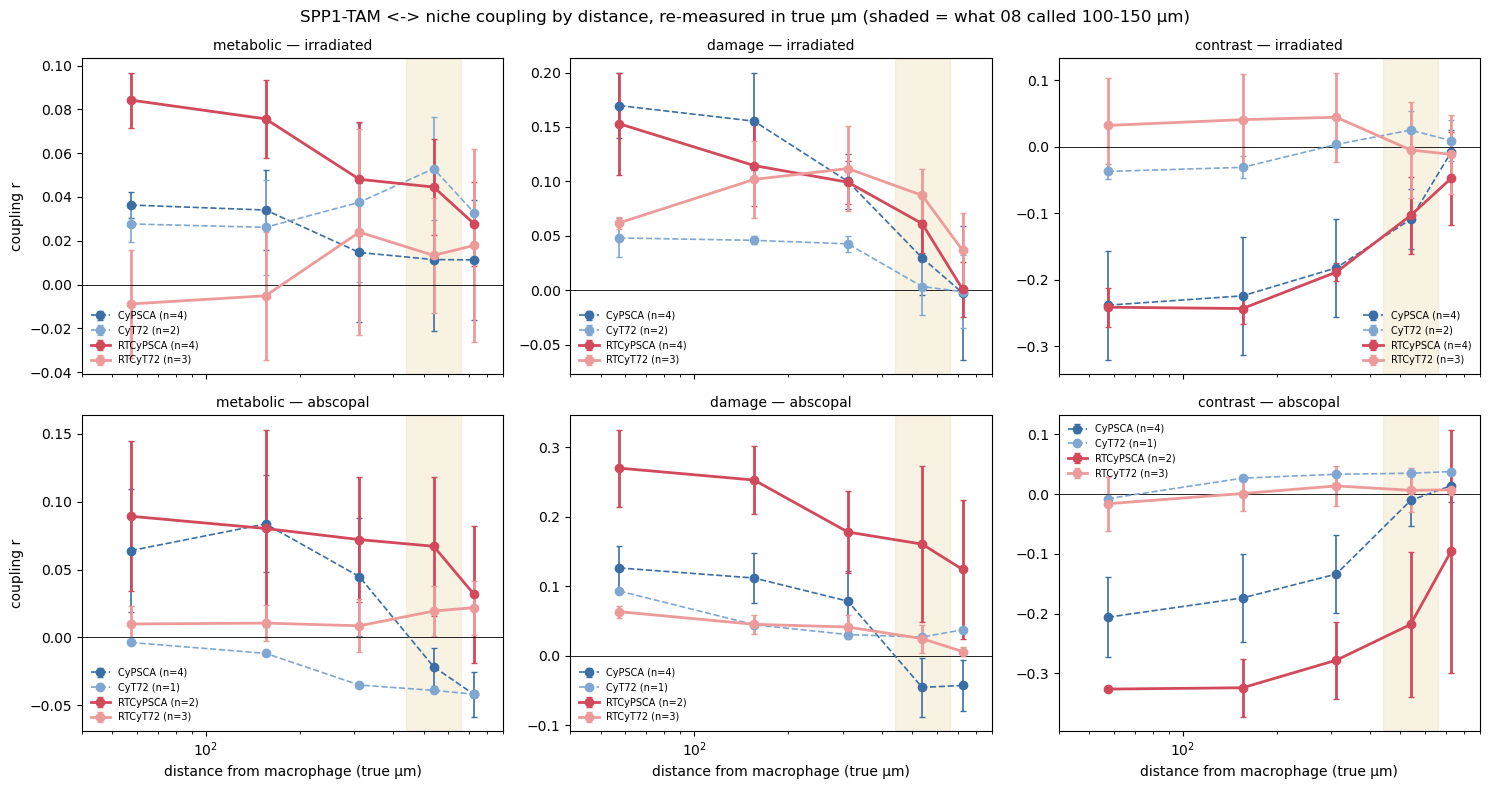

In [9]:
# (1) the correlogram, metabolic and damage tiers, by RT status and site — the 08 §C figure in µm
xs = [np.sqrt(max(a, 30) * b) for a, b in zip(BAND_EDGES_UM[:-1], BAND_EDGES_UM[1:])]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for i, s in enumerate((1, 2)):
    for j, tier in enumerate(TIER_ORDER):
        ax = axes[i, j]
        for arm in ARM_ORDER:
            d = TS[(TS.kind == "coupling") & (TS.tier == tier) & (TS.arm == arm) & (TS.site == s)
                   & (TS.region == "whole")]
            if d.empty: continue
            Y = d[[f"r_{b}" for b in BANDS]]
            ax.errorbar(xs, Y.mean(), yerr=Y.sem() if len(Y) > 1 else None, marker="o",
                        color=COL[arm], lw=2 if arm.startswith("RT") else 1.2,
                        ls="-" if arm.startswith("RT") else "--", capsize=2, label=f"{arm} (n={len(d)})")
        ax.axhline(0, color="k", lw=.6); ax.set_xscale("log"); ax.set_xlim(40, 900)
        ax.axvspan(440, 660, color="#f2e6c9", alpha=.5, zorder=0)
        ax.set_title(f"{tier} — {SITE[s]}", fontsize=10); ax.legend(fontsize=7, frameon=False)
for ax in axes[-1]: ax.set_xlabel("distance from macrophage (true µm)")
for ax in axes[:, 0]: ax.set_ylabel("coupling r")
fig.suptitle("SPP1-TAM <-> niche coupling by distance, re-measured in true µm "
             "(shaded = what 08 called 100-150 µm)", fontsize=12)
fig.tight_layout(); fig.savefig(FIG/"05_coupling_correlogram_true_um.png", dpi=220, bbox_inches="tight")
plt.show()

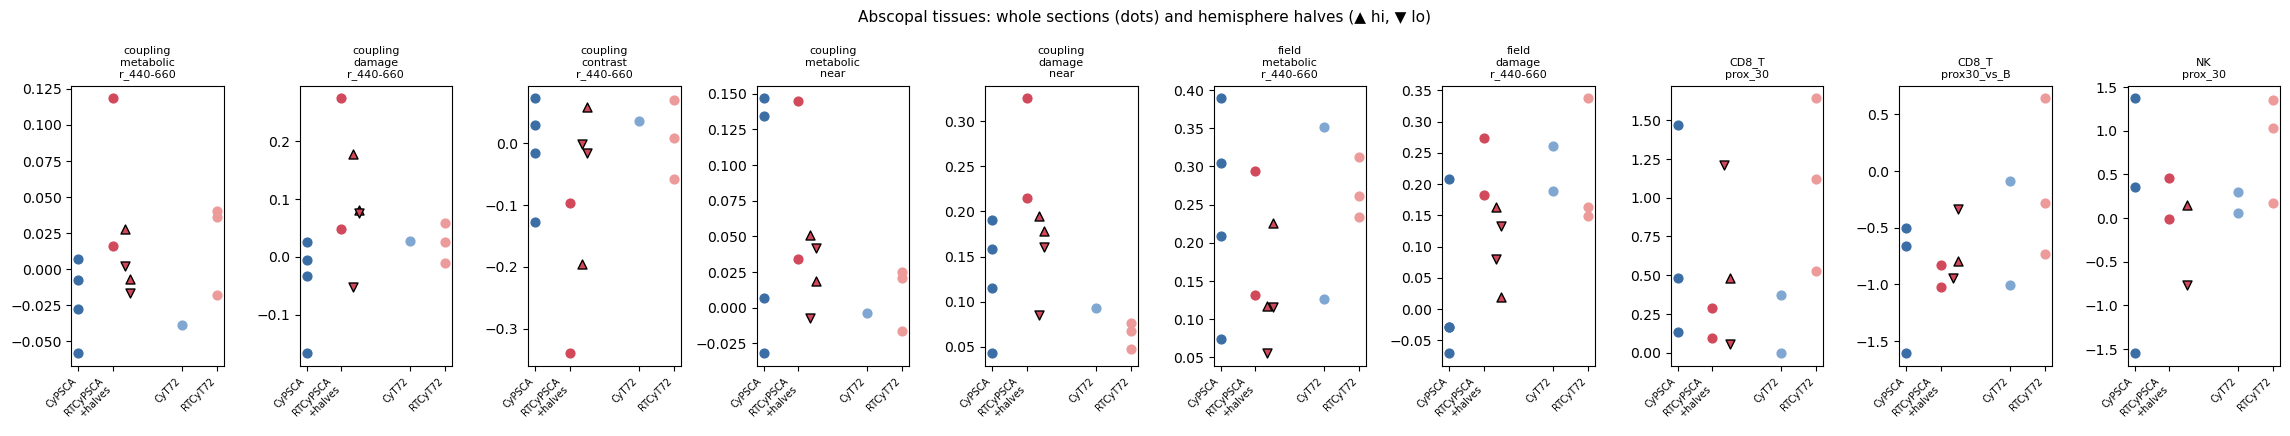

In [10]:
# (2) the hemisphere test: whole sections, halves, and the non-RT range, per readout
cols_ = [c for c in READ if c in H]
fig, axes = plt.subplots(1, len(cols_), figsize=(2.3*len(cols_), 4.4))
for ax, col in zip(np.atleast_1d(axes), cols_):
    for x, arm in [(0, "CyPSCA"), (1, "RTCyPSCA"), (3, "CyT72"), (4, "RTCyT72")]:
        v = whole.loc[AMW.index[(AMW.arm == arm) & (AMW.site == 2)], col].dropna() if col in whole else []
        ax.scatter(np.full(len(v), x), v, color=COL[arm], s=40, zorder=3)
    for k_, t in enumerate(HEMI_T):
        for h, mk in [("hi", "^"), ("lo", "v")]:
            v = H[(H.tissue == t) & (H.region == h)][col]
            ax.scatter([1.35 + 0.15*k_], v, marker=mk, color="#d1495b", edgecolor="k", s=42, zorder=4)
    ax.set_xticks([0, 1, 3, 4]); ax.set_xticklabels(["CyPSCA", "RTCyPSCA\n+halves", "CyT72", "RTCyT72"],
                                                    fontsize=7, rotation=45, ha="right")
    ax.set_title(col.replace("|", "\n"), fontsize=8)
fig.suptitle("Abscopal tissues: whole sections (dots) and hemisphere halves (▲ hi, ▼ lo)", fontsize=11)
fig.tight_layout(); fig.savefig(FIG/"05_hemisphere_test.png", dpi=220, bbox_inches="tight")
plt.show()

## 9. Summary

In [11]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print(f"\n[scale] µm = px x {MICRONS_PER_PIXEL} (no hires scale); bands {BANDS}")
print(f"        08's nominal 100-150 µm band = ~440-660 µm physical on a median slide -> band {OLD}")
print(f"[tissues] {len(TREATED_T)} treated; hemisphere-split sections: {HEMI_T}")

R = RANGE.set_index(["col", "site"])
print(f"\n[1. does RT extend the coupling RANGE? far-band coupling r (robust) and 08's ratio]")
for tier in ["metabolic", "damage", "contrast"]:
    for b in [f"r_{OLD}", f"r_660-800", f"ratio_{OLD}"]:
        for s in ("irradiated", "abscopal"):
            k = (f"coupling|{tier}|{b}", s)
            if k not in R.index: continue
            r = R.loc[k]
            print(f"    {tier:<9s} {b:<8s} {s:<10s} PSCA {r.d_PSCA:+.2f} ({r.n_PSCA})  TAG72 "
                  f"{r.d_TAG72:+.2f} ({r.n_TAG72})  agree={r.sign_agree}  p_main={r.p_main:.3f}")
print("\n[2. amplitude control — near-field coupling (0-110 µm) should NOT move]")
for tier in ["metabolic", "damage"]:
    for s in ("irradiated", "abscopal"):
        k = (f"coupling|{tier}|near", s)
        if k in R.index:
            r = R.loc[k]
            print(f"    {tier:<9s} {s:<10s} PSCA {r.d_PSCA:+.3f}  TAG72 {r.d_TAG72:+.3f}  p_main={r.p_main:.3f}")
print("\n[3. field control — the niche field's OWN far-band autocorrelation should NOT move]")
for tier in ["metabolic", "damage"]:
    for s in ("irradiated", "abscopal"):
        k = (f"field|{tier}|r_{OLD}", s)
        if k in R.index:
            r = R.loc[k]
            print(f"    {tier:<9s} {s:<10s} PSCA {r.d_PSCA:+.3f}  TAG72 {r.d_TAG72:+.3f}  p_main={r.p_main:.3f}")

old_claim = [(t, s) for t in ["metabolic", "damage"] for s in ("irradiated", "abscopal")
             if (f"coupling|{t}|r_{OLD}", s) in R.index
             and R.loc[(f"coupling|{t}|r_{OLD}", s), "sign_agree"] == True
             and R.loc[(f"coupling|{t}|r_{OLD}", s), "main"] > 0]
print(f"\n  -> 08's direction (more far-band coupling with RT, both backgrounds) at {OLD} µm in: "
      f"{old_claim if old_claim else 'NONE of the 4 tier x site cells'}")
for t_, s_ in old_claim:
    a_ = R.loc[(f"coupling|{t_}|near", s_)]; f_ = R.loc[(f"field|{t_}|r_{OLD}", s_)]
    print(f"     {t_}/{s_}: amplitude moved {a_.main:+.3f} (p={a_.p_main:.2f}); the niche field's own "
          f"{OLD} autocorrelation moved {f_.main:+.3f} (p={f_.p_main:.2f}, sign-agree={f_.sign_agree})")
    print("       -> " + ("FIELD CONTROL FAILS: the pathway field itself got coarser with RT, which "
                          "produces longer coupling\n          range with no change in how macrophages "
                          "couple to it." if f_.sign_agree == True and f_.main > 0 else
                          "field control passes."))

print("\n[4. hemisphere test, abscopal, PSCA background]")
if len(HT):
    print(HT[["readout", "delta_PSCA", "delta_TAG72", "halves_on_RT_side", "effect_over_noise"]]
          .round(2).to_string(index=False))
    rep = HT[(HT.halves_on_RT_side == "4/4") & (HT.effect_over_noise > 1)]
    print(f"  reproduced in all 4 halves AND larger than half-to-half noise: "
          f"{rep.readout.tolist() if len(rep) else 'none'}")
print(f"\n[files] {OUT}: 05_cell_scores.npz (cache), 05_correlogram_long.csv, 05_range_per_tissue.csv,"
      f"\n        05_range_rt_contrasts.csv, 05_hemisphere_test.csv, 05_hemisphere_readouts.csv, "
      f"05_halfhalf_null.csv")
print(f"[figures] {FIG}: 05_coupling_correlogram_true_um.png, 05_hemisphere_test.png")
print("=" * 100)

SUMMARY — report these back

[scale] µm = px x 0.34 (no hires scale); bands ['0-110', '110-220', '220-440', '440-660', '660-800']
        08's nominal 100-150 µm band = ~440-660 µm physical on a median slide -> band 440-660
[tissues] 24 treated; hemisphere-split sections: ['RTCyPSCA_2_3', 'RTCyPSCA_2_4']

[1. does RT extend the coupling RANGE? far-band coupling r (robust) and 08's ratio]
    metabolic r_440-660 irradiated PSCA +0.04 (3v4)  TAG72 -0.04 (3v2)  agree=False  p_main=0.940
    metabolic r_440-660 abscopal   PSCA +0.09 (2v4)  TAG72 +nan (3v1)  agree=nan  p_main=nan
    metabolic r_660-800 irradiated PSCA +0.03 (3v4)  TAG72 -0.01 (3v2)  agree=False  p_main=0.897
    metabolic r_660-800 abscopal   PSCA +0.07 (2v4)  TAG72 +nan (3v1)  agree=nan  p_main=nan
    metabolic ratio_440-660 irradiated PSCA +0.10 (3v4)  TAG72 +0.10 (3v2)  agree=True  p_main=0.674
    metabolic ratio_440-660 abscopal   PSCA +0.82 (2v3)  TAG72 +nan (0v0)  agree=nan  p_main=nan
    damage    r_440-660 irrad